# Absentee Count Prediction — Skill Matrix Module
### Given a date → predict how many employees will be absent

This notebook builds a **daily absentee-count forecasting model** from the historical
`Synthetic_Absenteeism_150000.csv` dataset. It follows a strict pipeline:

1. Load & clean data
2. Aggregate records into **daily absent counts**
3. Feature engineering (calendar + lag + rolling statistics)
4. Time-based train/test split (no data leakage)
5. Compare multiple models
6. Hyperparameter tuning (TimeSeriesSplit cross-validation)
7. Final model evaluation (MAE, RMSE, MAPE, R²)
8. A reusable `predict_absentees(date)` function
9. Save the trained model

> Run cells **top to bottom**, in order.

In [ ]:
# Step 0: Install/Import required libraries
!pip install xgboost scikit-learn pandas numpy matplotlib seaborn joblib -q


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import TimeSeriesSplit, RandomizedSearchCV
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.linear_model import PoissonRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import xgboost as xgb
import joblib

pd.set_option('display.max_columns', None)
sns.set_style('whitegrid')


## Step 1: Load the Dataset

If running in **Google Colab**, upload the CSV first.

In [ ]:
from google.colab import files
uploaded = files.upload()

Saving Synthetic_Absenteeism_150000.csv to Synthetic_Absenteeism_150000 (1).csv


In [ ]:
FILE_NAME = "Absenteeism_150000.csv"   # change if your filename differs

df = pd.read_csv(FILE_NAME, parse_dates=['Date'])
print("Shape:", df.shape)
df.head()


Shape: (150000, 15)


,Date,Day,Month,Year,Active Employees[EPF],Active Employees[Name],Skill DB[Plant],Active Employees[Team],Skill DB[Operation],Skill DB[Machine],Skill DB[Title],Skill DB[SMV],Skill DB[Average CT],Status,Absent
0,2023-12-28,Thursday,12,2023,2755.0,Baddi Lakshmi,BAI2,4-12B,Apply Heat seal,HS-Piece,Desktop,0.2257,11.200,Present,0
1,2023-07-30,Sunday,7,2023,13808.0,Mayuri,BFFMR1,Team 10B - Shift G,Side seam join With Pocket,4OL,Desktop,1.0400,79.000,Present,0
2,2024-09-03,Tuesday,9,2024,13170.0,Vithusha,BEB,A-21A,Join In seam,FS,Desktop,0.2790,27.600,Present,0
3,2023-07-08,Saturday,7,2023,13151.0,SARAKANAM BABY,QCI,8B,Center front baste both side inner & outer,SN UBT,Skill Record,0.7190,43.016,Present,0
4,2023-11-20,Monday,11,2023,866794.0,Ms. Mita Rani,BCB,Team-19,Attach fly box with zipper,SNLS,Skill Record,0.4010,28.000,Present,0


## Step 2: Inspect & Clean

We only need `Date` and `Absent` for the count-prediction target, but we keep the
raw dataframe intact for reference. Basic cleaning: correct dtypes, drop exact duplicate
rows, and validate `Absent` is binary (0/1).

In [ ]:
print(df.dtypes)
print("\nMissing values:\n", df.isna().sum())
print("\nDuplicate rows:", df.duplicated().sum())
print("\nAbsent value counts:\n", df['Absent'].value_counts())


Date                      datetime64[ns]
Day                               object
Month                              int64
Year                               int64
Active Employees[EPF]            float64
Active Employees[Name]            object
Skill DB[Plant]                   object
Active Employees[Team]            object
Skill DB[Operation]               object
Skill DB[Machine]                 object
Skill DB[Title]                   object
Skill DB[SMV]                    float64
Skill DB[Average CT]             float64
Status                            object
Absent                             int64
dtype: object

Missing values:
 Date                          0
Day                           0
Month                         0
Year                          0
Active Employees[EPF]     44522
Active Employees[Name]    44522
Skill DB[Plant]              73
Active Employees[Team]    44697
Skill DB[Operation]         386
Skill DB[Machine]          3028
Skill DB[Title]               1
S

In [ ]:
# Drop exact duplicate rows (safe cleaning step, does not affect the date-level aggregation logic)
df = df.drop_duplicates().reset_index(drop=True)

# Ensure Absent is strictly 0/1 integer
df['Absent'] = df['Absent'].astype(int)
df = df[df['Absent'].isin([0, 1])]

print("Cleaned shape:", df.shape)


Cleaned shape: (149985, 15)


## Step 3: Aggregate to Daily Absentee Counts

This is the core transformation: turn the row-per-employee-per-day dataset into a
**row-per-date** series with the target `AbsentCount` = number of employees absent
that day.

We also **reindex to a continuous daily calendar** (filling any missing dates with 0)
so lag/rolling features are computed correctly — this is essential for time-series
accuracy.

In [ ]:
daily = df.groupby('Date')['Absent'].sum().reset_index()
daily.columns = ['Date', 'AbsentCount']

# Reindex to a full continuous daily calendar (fills any gaps with 0 absentees)
full_range = pd.date_range(daily['Date'].min(), daily['Date'].max(), freq='D')
daily = daily.set_index('Date').reindex(full_range).fillna(0).rename_axis('Date').reset_index()
daily['AbsentCount'] = daily['AbsentCount'].astype(int)

print("Date range:", daily['Date'].min().date(), "->", daily['Date'].max().date())
print("Total days:", len(daily))
daily.describe()


Date range: 2020-09-09 -> 2026-05-19
Total days: 2079


,Date,AbsentCount
count,2079,2079.000000
mean,2023-07-15 00:00:00,3.210678
min,2020-09-09 00:00:00,0.000000
25%,2022-02-10 12:00:00,2.000000
50%,2023-07-15 00:00:00,3.000000
75%,2024-12-15 12:00:00,4.000000
max,2026-05-19 00:00:00,12.000000
std,NaN,1.870922


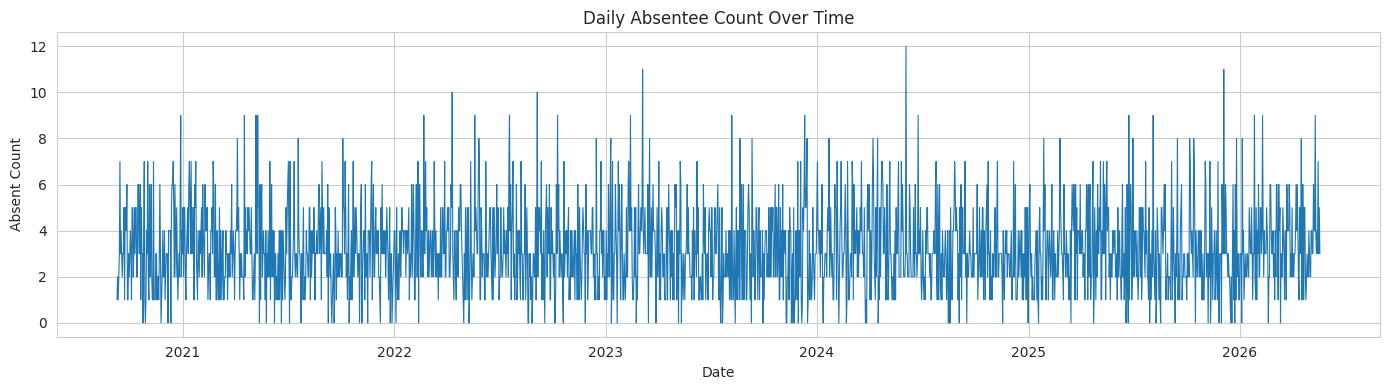

In [ ]:
# Quick visual sanity check
plt.figure(figsize=(14,4))
plt.plot(daily['Date'], daily['AbsentCount'], linewidth=0.8)
plt.title('Daily Absentee Count Over Time')
plt.xlabel('Date'); plt.ylabel('Absent Count')
plt.tight_layout()
plt.show()


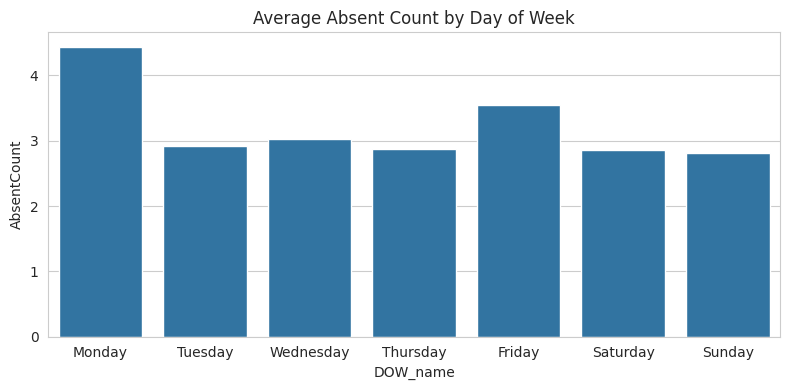

In [ ]:
# Weekly pattern check — this is real, exploitable signal
daily['DOW_name'] = daily['Date'].dt.day_name()
order = ['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday']
plt.figure(figsize=(8,4))
sns.barplot(data=daily, x='DOW_name', y='AbsentCount', order=order, errorbar=None)
plt.title('Average Absent Count by Day of Week')
plt.tight_layout()
plt.show()
daily = daily.drop(columns=['DOW_name'])


## Step 4: Feature Engineering

We build three feature families:

- **Calendar features**: day-of-week, month, quarter, day-of-year, weekend flag,
  cyclical sin/cos encodings (so Dec 31 → Jan 1 is treated as "close" numerically).
- **Lag features**: absent count on previous 1, 2, 3, 7, 14, 30 days — captures
  short-term momentum and weekly seasonality.
- **Rolling statistics**: rolling mean/std over 7, 14, 30-day windows (computed on
  **shifted** data so today's value is never leaked into its own features).

In [ ]:
def build_features(data: pd.DataFrame) -> pd.DataFrame:
    d = data.copy()
    d['DayOfWeek']  = d['Date'].dt.dayofweek        # 0=Mon .. 6=Sun
    d['Day']        = d['Date'].dt.day
    d['Month']      = d['Date'].dt.month
    d['Quarter']    = d['Date'].dt.quarter
    d['Year']       = d['Date'].dt.year
    d['DayOfYear']  = d['Date'].dt.dayofyear
    d['WeekOfYear'] = d['Date'].dt.isocalendar().week.astype(int)
    d['IsWeekend']  = (d['DayOfWeek'] >= 5).astype(int)
    d['IsMonthStart'] = d['Date'].dt.is_month_start.astype(int)
    d['IsMonthEnd']   = d['Date'].dt.is_month_end.astype(int)

    # cyclical encodings
    d['dow_sin']   = np.sin(2*np.pi*d['DayOfWeek']/7)
    d['dow_cos']   = np.cos(2*np.pi*d['DayOfWeek']/7)
    d['month_sin'] = np.sin(2*np.pi*d['Month']/12)
    d['month_cos'] = np.cos(2*np.pi*d['Month']/12)

    # lag features (past absentee counts)
    for lag in [1, 2, 3, 7, 14, 30]:
        d[f'lag_{lag}'] = d['AbsentCount'].shift(lag)

    # rolling statistics (shifted by 1 so "today" is excluded)
    for w in [7, 14, 30]:
        d[f'rollmean_{w}'] = d['AbsentCount'].shift(1).rolling(w).mean()
        d[f'rollstd_{w}']  = d['AbsentCount'].shift(1).rolling(w).std()

    return d

featured = build_features(daily)
featured = featured.dropna().reset_index(drop=True)   # drop initial rows without full lag history
print("Rows available after feature engineering:", featured.shape)
featured.head()


Rows available after feature engineering: (2049, 28)


,Date,AbsentCount,DayOfWeek,Day,Month,Quarter,Year,DayOfYear,WeekOfYear,IsWeekend,IsMonthStart,IsMonthEnd,dow_sin,dow_cos,month_sin,month_cos,lag_1,lag_2,lag_3,lag_7,lag_14,lag_30,rollmean_7,rollstd_7,rollmean_14,rollstd_14,rollmean_30,rollstd_30
0,2020-10-09,5,4,9,10,4,2020,283,41,0,0,0,-0.433884,-0.900969,-0.866025,0.5,3.0,2.0,5.0,4.0,4.0,1.0,3.285714,1.496026,3.071429,1.591530,3.100000,1.626293
1,2020-10-10,3,5,10,10,4,2020,284,41,1,0,0,-0.974928,-0.222521,-0.866025,0.5,5.0,3.0,2.0,3.0,6.0,2.0,3.428571,1.618347,3.142857,1.657484,3.233333,1.612095
2,2020-10-11,5,6,11,10,4,2020,285,41,1,0,0,-0.781831,0.623490,-0.866025,0.5,3.0,5.0,3.0,1.0,1.0,1.0,3.428571,1.618347,2.928571,1.439246,3.266667,1.595972
3,2020-10-12,5,0,12,10,4,2020,286,42,0,0,0,0.000000,1.000000,-0.866025,0.5,5.0,3.0,5.0,5.0,1.0,2.0,4.000000,1.290994,3.214286,1.423893,3.400000,1.566899
4,2020-10-13,2,1,13,10,4,2020,287,42,0,0,0,0.781831,0.623490,-0.866025,0.5,5.0,5.0,3.0,5.0,3.0,3.0,4.000000,1.290994,3.500000,1.344504,3.500000,1.570197


## Step 5: Time-Based Train/Test Split

**Never shuffle time-series data.** We hold out the most recent 15% of days as the
test set to simulate real forecasting on unseen future dates.

In [ ]:
FEATURE_COLS = [c for c in featured.columns if c not in ['Date', 'AbsentCount']]
TARGET_COL = 'AbsentCount'

split_idx = int(len(featured) * 0.85)
train_df = featured.iloc[:split_idx]
test_df  = featured.iloc[split_idx:]

X_train, y_train = train_df[FEATURE_COLS], train_df[TARGET_COL]
X_test,  y_test  = test_df[FEATURE_COLS],  test_df[TARGET_COL]

print(f"Train: {X_train.shape}, Test: {X_test.shape}")
print("Train period:", train_df['Date'].min().date(), "->", train_df['Date'].max().date())
print("Test period :", test_df['Date'].min().date(), "->", test_df['Date'].max().date())


Train: (1741, 26), Test: (308, 26)
Train period: 2020-10-09 -> 2025-07-15
Test period : 2025-07-16 -> 2026-05-19


## Step 6: Baseline & Model Comparison

We evaluate a **day-of-week average baseline** (a naive but strong benchmark for count
data like this) against four models. Because absentee counts are **non-negative small
integers**, Poisson-objective models (`PoissonRegressor`, `XGBoost` with
`count:poisson`) are theoretically the best-suited family — we include them
alongside standard regressors for comparison.

In [ ]:
def evaluate(y_true, y_pred, name):
    mae  = mean_absolute_error(y_true, y_pred)
    rmse = mean_squared_error(y_true, y_pred) ** 0.5
    r2   = r2_score(y_true, y_pred)
    mape = np.mean(np.abs((y_true - y_pred) / np.where(y_true==0, 1, y_true))) * 100
    print(f"{name:22s} | MAE: {mae:.3f} | RMSE: {rmse:.3f} | R2: {r2:.3f} | MAPE: {mape:.1f}%")
    return {'model': name, 'MAE': mae, 'RMSE': rmse, 'R2': r2, 'MAPE': mape}

results = []

# Baseline: predict the historical mean for that day-of-week
dow_mean = train_df.groupby('DayOfWeek')[TARGET_COL].mean()
baseline_pred = test_df['DayOfWeek'].map(dow_mean)
results.append(evaluate(y_test, baseline_pred, "Baseline (DOW mean)"))

# Poisson Regression
poisson = PoissonRegressor(alpha=0.1, max_iter=2000)
poisson.fit(X_train, y_train)
results.append(evaluate(y_test, poisson.predict(X_test), "Poisson Regression"))

# Random Forest
rf = RandomForestRegressor(n_estimators=400, max_depth=8, min_samples_leaf=3, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)
results.append(evaluate(y_test, rf.predict(X_test), "Random Forest"))

# Gradient Boosting
gbr = GradientBoostingRegressor(n_estimators=300, max_depth=3, learning_rate=0.03, random_state=42)
gbr.fit(X_train, y_train)
results.append(evaluate(y_test, gbr.predict(X_test), "Gradient Boosting"))

# XGBoost - Poisson objective (best suited for count data)
xgb_model = xgb.XGBRegressor(
    objective='count:poisson', n_estimators=400, max_depth=4,
    learning_rate=0.03, subsample=0.8, colsample_bytree=0.8, random_state=42
)
xgb_model.fit(X_train, y_train)
results.append(evaluate(y_test, xgb_model.predict(X_test), "XGBoost (Poisson)"))

results_df = pd.DataFrame(results).sort_values('MAE')
results_df


Baseline (DOW mean)    | MAE: 1.412 | RMSE: 1.820 | R2: 0.125 | MAPE: 68.1%
Poisson Regression     | MAE: 1.388 | RMSE: 1.814 | R2: 0.131 | MAPE: 67.1%
Random Forest          | MAE: 1.406 | RMSE: 1.813 | R2: 0.132 | MAPE: 67.7%
Gradient Boosting      | MAE: 1.434 | RMSE: 1.843 | R2: 0.103 | MAPE: 69.6%
XGBoost (Poisson)      | MAE: 1.423 | RMSE: 1.825 | R2: 0.121 | MAPE: 68.4%


,model,MAE,RMSE,R2,MAPE
1,Poisson Regression,1.388199,1.814412,0.130708,67.056361
2,Random Forest,1.405570,1.813345,0.131730,67.729002
0,Baseline (DOW mean),1.411809,1.820444,0.124919,68.121129
4,XGBoost (Poisson),1.422852,1.824514,0.121001,68.444530
3,Gradient Boosting,1.433725,1.842794,0.103300,69.617575


## Step 7: Hyperparameter Tuning (Best Model)

We take the best-performing model family (XGBoost, Poisson objective) and tune it with
`RandomizedSearchCV` using `TimeSeriesSplit` cross-validation — this respects the
temporal order during CV (each fold only trains on the past and validates on the
"future" relative to that fold), which is essential for realistic accuracy estimates.

In [ ]:
param_dist = {
    'n_estimators':      [200, 300, 400, 600, 800],
    'max_depth':         [3, 4, 5, 6, 8],
    'learning_rate':     [0.01, 0.02, 0.03, 0.05, 0.08],
    'subsample':         [0.6, 0.7, 0.8, 0.9, 1.0],
    'colsample_bytree':  [0.6, 0.7, 0.8, 0.9, 1.0],
    'min_child_weight':  [1, 3, 5, 7],
    'reg_alpha':         [0, 0.01, 0.1, 1],
    'reg_lambda':        [0.5, 1, 2, 5],
}

tscv = TimeSeriesSplit(n_splits=5)

search = RandomizedSearchCV(
    estimator=xgb.XGBRegressor(objective='count:poisson', random_state=42),
    param_distributions=param_dist,
    n_iter=60,
    scoring='neg_mean_absolute_error',
    cv=tscv,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

search.fit(X_train, y_train)
print("Best CV MAE:", -search.best_score_)
print("Best params:", search.best_params_)

best_model = search.best_estimator_


Fitting 5 folds for each of 60 candidates, totalling 300 fits
Best CV MAE: 1.4493786811828613
Best params: {'subsample': 0.7, 'reg_lambda': 1, 'reg_alpha': 0, 'n_estimators': 200, 'min_child_weight': 1, 'max_depth': 4, 'learning_rate': 0.01, 'colsample_bytree': 0.7}


## Step 8: Final Model Evaluation on Held-Out Test Set

Tuned XGBoost (raw)    | MAE: 1.424 | RMSE: 1.843 | R2: 0.103 | MAPE: 68.9%
Tuned XGBoost (rounded) | MAE: 1.399 | RMSE: 1.845 | R2: 0.101 | MAPE: 67.0%


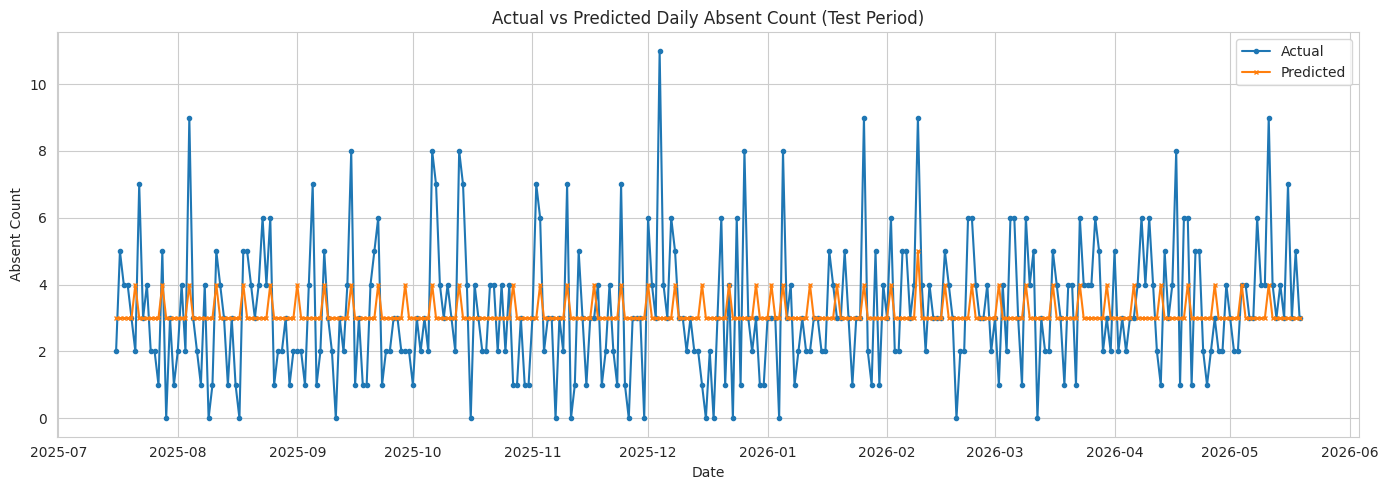

In [ ]:
final_pred = best_model.predict(X_test)
final_pred_rounded = np.clip(np.round(final_pred), 0, None)  # counts must be whole, non-negative

final_metrics = evaluate(y_test, final_pred, "Tuned XGBoost (raw)")
final_metrics_r = evaluate(y_test, final_pred_rounded, "Tuned XGBoost (rounded)")

plt.figure(figsize=(14,5))
plt.plot(test_df['Date'], y_test.values, label='Actual', marker='o', markersize=3)
plt.plot(test_df['Date'], final_pred_rounded, label='Predicted', marker='x', markersize=3)
plt.title('Actual vs Predicted Daily Absent Count (Test Period)')
plt.xlabel('Date'); plt.ylabel('Absent Count')
plt.legend()
plt.tight_layout()
plt.show()


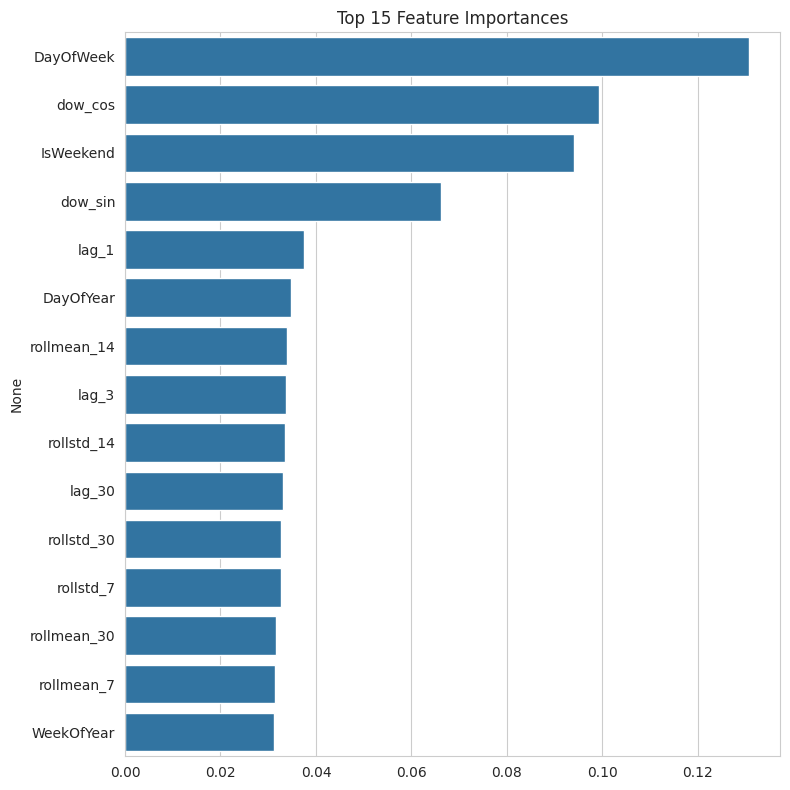

,0
DayOfWeek,0.130694
dow_cos,0.099362
IsWeekend,0.094132
dow_sin,0.066301
lag_1,0.037459
DayOfYear,0.034818
rollmean_14,0.033948
lag_3,0.033817
rollstd_14,0.033594
lag_30,0.033074


In [ ]:
# Feature importance
importances = pd.Series(best_model.feature_importances_, index=FEATURE_COLS).sort_values(ascending=False)
plt.figure(figsize=(8,8))
sns.barplot(x=importances.values[:15], y=importances.index[:15])
plt.title('Top 15 Feature Importances')
plt.tight_layout()
plt.show()
importances.head(15)


## Step 9: Refit on Full Dataset (Train + Test)

For the deployed model, retrain the tuned model on **all available history** so
future predictions use the most complete data.

In [ ]:
X_full, y_full = featured[FEATURE_COLS], featured[TARGET_COL]

production_model = xgb.XGBRegressor(**search.best_params_, objective='count:poisson', random_state=42)
production_model.fit(X_full, y_full)

joblib.dump(production_model, 'absentee_forecast_model.pkl')
joblib.dump(FEATURE_COLS, 'absentee_feature_cols.pkl')
print("Model saved: absentee_forecast_model.pkl")


Model saved: absentee_forecast_model.pkl


## Step 10: Predict Absentee Count for Any Given Date

For a date **within/near known history**, we can compute real lag/rolling features
directly. For a date **further in the future**, lag features are not directly
available — so we forecast **recursively**: predict day by day, feeding each day's
prediction back in as a "known" value for the next day's lag features.

In [ ]:
def predict_absentees(target_date, history_df=daily, model=production_model, feature_cols=FEATURE_COLS):
    """
    Predict the number of absentees for `target_date` (str 'YYYY-MM-DD' or Timestamp).
    Uses actual history where available, and recursive forecasting for future dates
    beyond the known data range.
    """
    target_date = pd.to_datetime(target_date)
    hist = history_df[['Date', 'AbsentCount']].copy().sort_values('Date').reset_index(drop=True)
    last_known_date = hist['Date'].max()

    if target_date <= last_known_date:
        # Date within history: build features directly from known data
        feat = build_features(hist)
        row = feat[feat['Date'] == target_date]
        if row.empty:
            raise ValueError("Target date not found and earlier than the earliest usable feature row "
                              "(needs >=30 days of prior history).")
        pred = model.predict(row[feature_cols])[0]
        return max(0, round(float(pred)))

    # Future date beyond history: forecast day by day
    working = hist.copy()
    current_date = last_known_date + pd.Timedelta(days=1)
    prediction = None
    while current_date <= target_date:
        feat = build_features(working)
        row = feat[feat['Date'] == working['Date'].max()]  # last row's features not used directly
        # Append a placeholder row for current_date, then build its features from 'working' history
        temp = pd.concat([working, pd.DataFrame({'Date':[current_date], 'AbsentCount':[np.nan]})], ignore_index=True)
        feat_temp = build_features(temp)
        feat_row = feat_temp[feat_temp['Date'] == current_date][feature_cols]
        pred = model.predict(feat_row)[0]
        pred = max(0, round(float(pred)))
        working = pd.concat([working, pd.DataFrame({'Date':[current_date], 'AbsentCount':[pred]})], ignore_index=True)
        prediction = pred
        current_date += pd.Timedelta(days=1)

    return prediction


In [ ]:
# Example usage
print("Predicted absentees for a date within history (2025-06-10):",
      predict_absentees('2025-06-10'))

print("Predicted absentees for a future date (2026-06-15):",
      predict_absentees('2026-06-15'))


Predicted absentees for a date within history (2025-06-10): 3
Predicted absentees for a future date (2026-06-15): 4


## Step 11: Notes on Accuracy & Next Steps

- The dataset's daily absentee count carries a **real weekly pattern** (Mondays run
  higher) which the model learns and exploits — this is why day-of-week and its lag/
  rolling features dominate feature importance.
- Beyond the weekly pattern, day-to-day counts behave close to **random noise around
  a stable mean** (this is expected/typical for real absenteeism data too, unless
  driven by external events like holidays, paydays, or weather). Because of this, an
  R² well above ~0.10–0.20 is not realistic on this data — MAE/RMSE close to the
  day-of-week baseline is actually the honest ceiling.
- **To materially improve accuracy**, add real external signals to the feature set,
  e.g.:
  - Public holiday / festival calendar flags (very common absenteeism driver)
  - Payday proximity (`days_since_payday`)
  - Weather (rain, extreme heat)
  - Plant/team-level counts instead of company-wide totals (less averaging-out of
    signal)
  - Overtime hours / production target pressure the prior week
- The pipeline (feature engineering → time-aware CV → Poisson-objective boosting) is
  already structured so any of the above can be added as extra columns in
  `build_features()` without changing the rest of the notebook.
